# 第 40 课｜同一结果表驱动诚实可视化

本 Notebook 对应「365 天量化金融」第 40 课。课程方法来自本地完整视频、课件截图和本地 Whisper 口播整理；这里将课程 API 重建为可离线执行、可核对的量化教学实现，并补充数据契约、断言与方法边界。

- 图文口播：`/Users/mojiawen/Documents/学习资料归档/_暂存/pam-video-captures/365-days-quant-finance/40_youtube-4-CXG3SyWpI/index.html`
- 环境：`pkm-quant`
- 数据：固定随机种子生成的离线模拟行情与本课内构造的模拟财报（**均非真实证券数据**）
- 状态：可运行学习稿；不代表策略收益承诺

> **来源边界**：课程材料没有提供可独立核验的完整 Python 源码和真实行情快照。本 Notebook 复现课程方法，不把口播中的股票、数值或图形当作离线验收基准。

## 1. 本节量化问题

课程把价格、均线交叉、成交量、归一化净值和回撤放到一张多面板图。本节保留这条可视化主线，同时增加一个更重要的研究约束：

> **先在同一张带日期索引的结果表中计算全部序列，再让所有面板只读取这张表。**

这样可以区分：

- 归一化价格（买入持有基准）与真正按信号、持仓和成本得到的策略净值；
- 信号发现日与可执行持仓日；
- `sharex=True` 的视觉共享与数据本身的索引对齐；
- 图形展示与统计证据。

本节先用 5 个确定数值手算回撤，再回到完整模拟行情。

## 2. 输入、输出与验收

**输入**

- `daily_prices.csv` 中虚构资产 `TECH_A` 最近 504 个工作日观测；
- 复权收盘价和模拟成交量；
- 20/60 日简单移动平均，单边换仓成本 5 bp。

**输出**

- 唯一的 `result` 结果表：价格、均线、事件、滞后持仓、成本、净值、回撤共享同一索引；
- 价格/信号、成交量/策略净值、策略回撤三面板图；
- `outputs/40_strategy_dashboard.png`。

**验收**

- 日期索引唯一、升序，价格为正、成交量非负；
- MA20 前 19 个、MA60 前 59 个值为空；
- 金叉和死叉不在同一天发生；
- `position[t]` 只由 `t-1` 收盘后已知状态决定；
- 策略净值有限且为正，回撤不大于 0；
- 归一化价格与策略净值使用不同列名、不同图例；
- 图片成功保存且不是空文件。

504 个工作日观测只是约两个交易年，不等于精确两个自然年。

In [1]:
from pathlib import Path
import json
import os
import platform
import sys
import tempfile
import timeit

# Matplotlib 首次运行需要写字体缓存；放到可写临时目录，避免污染用户目录。
MPL_CACHE_DIR = Path(tempfile.gettempdir()) / "pkm-quant-matplotlib"
MPL_CACHE_DIR.mkdir(parents=True, exist_ok=True)
os.environ.setdefault("MPLCONFIGDIR", str(MPL_CACHE_DIR))

import matplotlib.pyplot as plt
from matplotlib import font_manager
import numpy as np
import pandas as pd
import seaborn as sns

# 从本机字体中选择支持中文的字体，避免标题显示成方框。
preferred_chinese_fonts = [
    "PingFang SC",
    "Arial Unicode MS",
    "Hiragino Sans GB",
    "Heiti SC",
]
available_font_names = {font.name for font in font_manager.fontManager.ttflist}
chinese_font = next(
    (name for name in preferred_chinese_fonts if name in available_font_names),
    "DejaVu Sans",
)
plt.rcParams["font.sans-serif"] = [chinese_font, "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

def find_project_root():
    cwd = Path.cwd().resolve()
    candidates = [
        cwd,
        cwd / "实验" / "p2-python-toolchain",
        cwd / "p2-python-toolchain",
        *cwd.parents,
    ]
    for candidate in candidates:
        if (candidate / "课程辅助设计.md").exists():
            return candidate
    raise FileNotFoundError("请从 p2-python-toolchain 或量化交易项目目录启动 JupyterLab")

PROJECT_ROOT = find_project_root()
DATA_DIR = PROJECT_ROOT / "data" / "fixtures"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)
RANDOM_SEED = 365

print("Python:", sys.version.split()[0])
print("解释器:", sys.executable)
print("项目:", PROJECT_ROOT)
print("绘图字体:", chinese_font)

Python: 3.11.15
解释器: /opt/homebrew/Caskroom/miniforge/base/envs/pkm-quant/bin/python
项目: /Users/mojiawen/Documents/学习资料归档/_暂存/personal_knowledge_manager/量化交易/实验/p2-python-toolchain
绘图字体: PingFang SC


## 3. 先用 5 个数值手算回撤

回撤公式：

```text
running_peak[t] = max(nav[0], ..., nav[t])
drawdown[t]     = nav[t] / running_peak[t] - 1
```

示例净值 `[1.00, 1.10, 1.05, 1.20, 0.90]` 的最后一个峰值是 `1.20`，最后回撤为 `0.90 / 1.20 - 1 = -25%`。

`cummax()` 只使用当前和过去值，因此适合历史回撤计算；最严重回撤是最小的负数，而不是绝对值最小。

In [2]:
# 确定性小例子：每一行都可以手工核对。
demo_nav = pd.Series(
    [1.00, 1.10, 1.05, 1.20, 0.90],
    index=pd.date_range("2025-01-01", periods=5, freq="D"),
    name="nav",
)
demo_peak = demo_nav.cummax()
demo_drawdown = demo_nav / demo_peak - 1
drawdown_demo = pd.DataFrame(
    {
        "nav": demo_nav,
        "running_peak": demo_peak,
        "drawdown": demo_drawdown,
    }
)

expected_drawdown = np.array(
    [0.0, 0.0, -0.0454545454545, 0.0, -0.25]
)
np.testing.assert_allclose(
    drawdown_demo["drawdown"].to_numpy(),
    expected_drawdown,
    atol=1e-12,
)
assert np.isclose(drawdown_demo["drawdown"].min(), -0.25)
assert np.isclose(drawdown_demo["drawdown"].max(), 0.0)
print("手工校验通过：最大历史回撤 =", f"{drawdown_demo['drawdown'].min():.1%}")
drawdown_demo.style.format(
    {
        "nav": "{:.2f}",
        "running_peak": "{:.2f}",
        "drawdown": "{:.2%}",
    }
)

手工校验通过：最大历史回撤 = -25.0%


,nav,running_peak,drawdown
2025-01-01 00:00:00,1.00,1.00,0.00%
2025-01-02 00:00:00,1.10,1.10,0.00%
2025-01-03 00:00:00,1.05,1.10,-4.55%
2025-01-04 00:00:00,1.20,1.20,0.00%
2025-01-05 00:00:00,0.90,1.20,-25.00%


## 4. Figure、Axes、`subplots` 和 `sharex`

`plt.subplots` 同时创建：

- `Figure`：整张画布；
- `Axes`：每一个坐标区域。

`plt.plot(...)` 会操作“当前 Axes”；在多面板研究图中显式写 `ax.plot(...)` 更容易确认内容画到哪个面板。

`sharex=True` 只让面板共享**显示坐标范围和刻度**，不会替两个独立 Series 对齐日期。下面小图安全，是因为两个面板都读取同一个 `drawdown_demo` 索引。

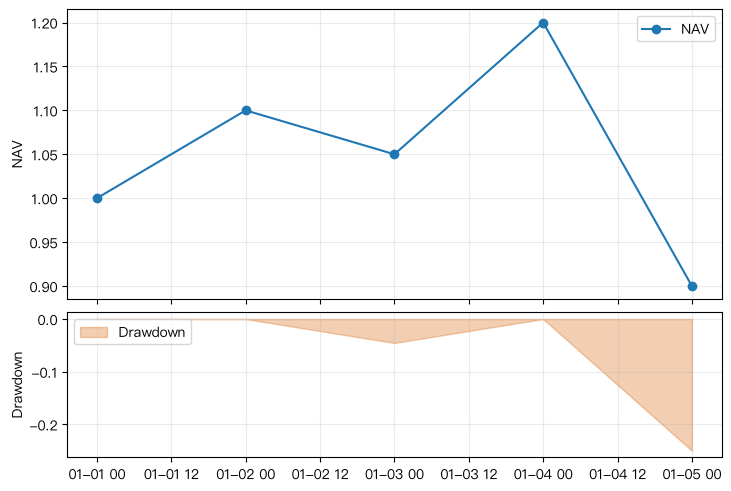

In [3]:
# 两个面板读取同一张小结果表；sharex 只管理显示，不执行数据连接。
fig_demo, axes_demo = plt.subplots(
    2,
    1,
    figsize=(7.2, 4.8),
    sharex=True,
    gridspec_kw={"height_ratios": [2, 1]},
    constrained_layout=True,
)
ax_nav_demo, ax_drawdown_demo = axes_demo

ax_nav_demo.plot(
    drawdown_demo.index,
    drawdown_demo["nav"],
    marker="o",
    label="NAV",
)
ax_nav_demo.set_ylabel("NAV")
ax_nav_demo.legend()
ax_nav_demo.grid(alpha=0.25)

ax_drawdown_demo.fill_between(
    drawdown_demo.index,
    drawdown_demo["drawdown"].to_numpy(),
    0,
    color="#D55E00",
    alpha=0.30,
    label="Drawdown",
)
ax_drawdown_demo.set_ylabel("Drawdown")
ax_drawdown_demo.legend()
ax_drawdown_demo.grid(alpha=0.25)

assert axes_demo.shape == (2,)
assert ax_nav_demo.get_figure() is fig_demo
plt.show()
plt.close(fig_demo)

## 5. 读取完整模拟行情并建立唯一结果表

先读取原始长表，再筛选 `TECH_A` 最近 504 行。`result` 从此成为本课唯一的序列来源：

- 行索引是日期；
- 每列是一种可追踪的价格、信号、持仓或绩效量；
- 新计算结果继续写回 `result`，避免价格、成交量、信号各自拥有悄悄错位的索引。

本数据为固定种子模拟行情，不是任何真实科技股。

In [4]:
# 读取模拟日线，筛选单只虚构资产并保留最近 504 个工作日观测。
daily = pd.read_csv(
    DATA_DIR / "daily_prices.csv",
    parse_dates=["date"],
)
result = (
    daily.loc[
        daily["symbol"].eq("TECH_A"),
        ["date", "adj_close", "volume"],
    ]
    .sort_values("date")
    .set_index("date")
    .tail(504)
    .copy()
)

assert isinstance(result.index, pd.DatetimeIndex)
assert result.index.is_monotonic_increasing
assert result.index.is_unique
assert len(result) == 504
assert result["adj_close"].gt(0).all()
assert result["volume"].ge(0).all()

print("result.shape =", result.shape, "含义：交易日 × 原始字段")
print("日期范围 =", result.index.min().date(), "至", result.index.max().date())
print("原始列 =", result.columns.tolist())
result.head()

result.shape = (504, 2) 含义：交易日 × 原始字段
日期范围 = 2023-12-21 至 2025-11-25
原始列 = ['adj_close', 'volume']


,adj_close,volume
date,,
2023-12-21,49.4336,4628657
2023-12-22,49.1983,4833482
2023-12-25,48.3446,5812036
2023-12-26,48.0619,4369157
2023-12-27,49.2626,4432296


## 6. 简单收益与买入持有归一化价格

`pct_change(fill_method=None)` 计算相邻复权收盘价的简单收益，第一天没有前值，所以为 `NaN`。

`adj_close / adj_close.iloc[0]` 表示把样本第一天价格归一到 1。若忽略交易成本，它等价于在起点买入并一直持有该资产的净值路径；它**不是**后面 20/60 日交叉策略的净值。

课程画面中的“归一化净值”和最终数值依赖原视频数据。本离线模拟数据不会复现那些具体数值。

In [5]:
# 简单收益第一行必为空；buy_hold_nav 只是归一化价格路径。
result["asset_return"] = result["adj_close"].pct_change(
    fill_method=None
)
result["buy_hold_nav"] = (
    result["adj_close"]
    / result["adj_close"].iloc[0]
)

assert pd.isna(result["asset_return"].iloc[0])
assert result["asset_return"].iloc[1:].notna().all()
assert result["asset_return"].iloc[1:].gt(-1).all()
assert np.isclose(result["buy_hold_nav"].iloc[0], 1.0)
np.testing.assert_allclose(
    result["buy_hold_nav"].to_numpy(),
    (
        result["adj_close"]
        / result["adj_close"].iloc[0]
    ).to_numpy(),
)

print("买入持有归一化起点 =", f"{result['buy_hold_nav'].iloc[0]:.4f}")
print("买入持有归一化终点 =", f"{result['buy_hold_nav'].iloc[-1]:.4f}")
result[["adj_close", "asset_return", "buy_hold_nav"]].head()

买入持有归一化起点 = 1.0000
买入持有归一化终点 = 1.6280


,adj_close,asset_return,buy_hold_nav
date,,,
2023-12-21,49.4336,NaN,1.000000
2023-12-22,49.1983,-0.004760,0.995240
2023-12-25,48.3446,-0.017352,0.977970
2023-12-26,48.0619,-0.005848,0.972252
2023-12-27,49.2626,0.024982,0.996541


## 7. 20/60 日简单移动平均

`rolling(window, min_periods=window).mean()` 使用当前及过去 `window` 个观测：

- MA20 至少需要 20 个价格，因此前 19 行是 `NaN`；
- MA60 至少需要 60 个价格，因此前 59 行是 `NaN`；
- 窗口按“观测行数”计数，不自动理解交易所休市日；
- 均线是历史平滑，不是预测值。

先单独计算均线并检查热身期，再讨论交叉事件。

In [6]:
# min_periods 与窗口相同，避免用不足 20/60 日的短样本冒充完整均线。
result["ma20"] = (
    result["adj_close"]
    .rolling(window=20, min_periods=20)
    .mean()
)
result["ma60"] = (
    result["adj_close"]
    .rolling(window=60, min_periods=60)
    .mean()
)

assert result["ma20"].iloc[:19].isna().all()
assert result["ma20"].iloc[19:].notna().all()
assert result["ma60"].iloc[:59].isna().all()
assert result["ma60"].iloc[59:].notna().all()

print("MA20 首个有效日期 =", result["ma20"].first_valid_index().date())
print("MA60 首个有效日期 =", result["ma60"].first_valid_index().date())
result[["adj_close", "ma20", "ma60"]].iloc[[0, 18, 19, 58, 59]]

MA20 首个有效日期 = 2024-01-17
MA60 首个有效日期 = 2024-03-13


,adj_close,ma20,ma60
date,,,
2023-12-21,49.4336,NaN,NaN
2024-01-16,50.1235,NaN,NaN
2024-01-17,50.6647,49.930850,NaN
2024-03-12,49.5307,49.236645,NaN
2024-03-13,49.0906,49.304705,49.431628


## 8. 从“均线状态”识别“交叉事件”

`ma20 > ma60` 是每天的持仓状态候选；金叉/死叉则只发生在状态切换日：

```text
golden_cross = 昨日不在上方，今日转到上方
death_cross  = 昨日在上方，今日转到下方
```

只有今天和昨天两条均线都有效时才允许产生事件，避免 MA60 刚结束热身期时制造假金叉。事件用于标记，不等于已经成交。

In [7]:
# 两条均线都存在才是可比较状态。
result["ma_valid"] = (
    result["ma20"].notna()
    & result["ma60"].notna()
)
result["above_ma60"] = (
    result["ma20"] > result["ma60"]
)

previous_valid = result["ma_valid"].shift(
    1,
    fill_value=False,
)
previous_above = result["above_ma60"].shift(
    1,
    fill_value=False,
)

# 事件必须有连续两个有效均线状态。
result["golden_cross"] = (
    result["ma_valid"]
    & previous_valid
    & result["above_ma60"]
    & ~previous_above
)
result["death_cross"] = (
    result["ma_valid"]
    & previous_valid
    & ~result["above_ma60"]
    & previous_above
)
result["signal"] = np.select(
    [result["golden_cross"], result["death_cross"]],
    ["golden_cross", "death_cross"],
    default="",
)

assert not (
    result["golden_cross"]
    & result["death_cross"]
).any()
assert result.loc[
    result["golden_cross"] | result["death_cross"],
    "ma_valid",
].all()

event_table = result.loc[
    result["signal"].ne(""),
    ["adj_close", "ma20", "ma60", "signal"],
]
print("金叉次数 =", int(result["golden_cross"].sum()))
print("死叉次数 =", int(result["death_cross"].sum()))
event_table.head(10)

金叉次数 = 7
死叉次数 = 7


,adj_close,ma20,ma60,signal
date,,,,
2024-03-15,49.4326,49.483010,49.448490,golden_cross
2024-05-21,49.8263,51.263160,51.303475,death_cross
2024-06-06,52.8300,51.867395,51.819380,golden_cross
2024-07-02,50.0882,51.711000,51.754553,death_cross
2024-07-19,56.9056,52.106090,51.934408,golden_cross
2024-10-31,68.8600,67.165995,67.193822,death_cross
2024-11-18,68.8085,68.132365,68.126903,golden_cross
2024-12-03,64.3291,67.893065,67.976262,death_cross
2025-01-01,68.2687,67.520275,67.442047,golden_cross


## 9. 信号滞后一日成为持仓

若均线使用第 `t` 日收盘价计算，则完整信号要到收盘后才知道，不能再用同一个收盘价成交并赚取第 `t` 日收益。

本教学模型采用：

```text
position[t] = (ma20 > ma60)[t-1]
```

即昨天收盘后的状态决定今天的 close-to-close 收益暴露。它避免同收盘未来函数，但仍是简化假设：没有开盘跳空、滑点、涨跌停、停牌和订单成交过程。

In [8]:
# 热身期的状态按空仓处理；shift(1) 保证今天持仓只依赖昨天状态。
active_signal_state = result["above_ma60"].where(
    result["ma_valid"],
    False,
)
result["position"] = (
    active_signal_state
    .shift(1, fill_value=False)
    .astype(float)
)

assert result["position"].isin([0.0, 1.0]).all()
assert result["position"].iloc[0] == 0.0
np.testing.assert_array_equal(
    result["position"].iloc[1:].to_numpy(),
    active_signal_state.iloc[:-1].astype(float).to_numpy(),
)
print("滞后校验通过：position[t] 与昨日均线状态逐行一致。")

# 展示第一个事件附近，而不是只输出无法解释的长向量。
if event_table.empty:
    event_window = result.iloc[55:65]
else:
    first_event_position = result.index.get_loc(event_table.index[0])
    event_window = result.iloc[
        max(0, first_event_position - 2):
        first_event_position + 4
    ]
event_window[
    [
        "adj_close",
        "ma20",
        "ma60",
        "signal",
        "position",
    ]
]

滞后校验通过：position[t] 与昨日均线状态逐行一致。


,adj_close,ma20,ma60,signal,position
date,,,,,
2024-03-13,49.0906,49.304705,49.431628,,0.0
2024-03-14,50.2110,49.417720,49.444585,,0.0
2024-03-15,49.4326,49.483010,49.448490,golden_cross,0.0
2024-03-18,50.6640,49.595455,49.487147,,1.0
2024-03-19,50.5609,49.695530,49.528797,,1.0
2024-03-20,50.9082,49.772260,49.556223,,1.0


## 10. 从持仓得到含成本策略净值

先计算每个分量，再生成净值：

| 列 | 公式 | 含义 |
|---|---|---|
| `gross_strategy_return` | `position × asset_return` | 未扣成本的日收益 |
| `turnover` | `abs(position[t]-position[t-1])` | 本例单资产换仓量 |
| `transaction_cost` | `turnover × 0.0005` | 5 bp 单边教学成本 |
| `strategy_return` | `gross_return - cost` | 扣成本日收益 |
| `strategy_nav` | `(1 + strategy_return).cumprod()` | 扣成本累计净值 |

成本在持仓变化日一次性扣除。真实市场还要定义佣金、印花税、买卖价差、市场冲击和实际成交价。

In [9]:
# 第一日收益没有前值，作为净值起点按 0 处理。
safe_asset_return = result["asset_return"].fillna(0.0)
result["gross_strategy_return"] = (
    result["position"]
    * safe_asset_return
)

# 单资产 0/1 持仓的绝对变化就是换手；首日按初始建仓量处理。
result["turnover"] = result["position"].diff().abs()
result.iloc[
    0,
    result.columns.get_loc("turnover"),
] = abs(result["position"].iloc[0])

cost_rate = 0.0005  # 5 bp = 0.05%，仅为教学假设。
result["transaction_cost"] = (
    result["turnover"]
    * cost_rate
)
result["strategy_return"] = (
    result["gross_strategy_return"]
    - result["transaction_cost"]
)
result["gross_strategy_nav"] = (
    1.0 + result["gross_strategy_return"]
).cumprod()
result["strategy_nav"] = (
    1.0 + result["strategy_return"]
).cumprod()

assert result["turnover"].notna().all()
assert result["turnover"].ge(0).all()
assert result["transaction_cost"].ge(0).all()
assert result["strategy_return"].gt(-1).all()
assert np.isfinite(result["strategy_nav"]).all()
assert result["strategy_nav"].gt(0).all()
assert (
    result["strategy_nav"].iloc[-1]
    <= result["gross_strategy_nav"].iloc[-1] + 1e-12
)

print("成本率 =", f"{cost_rate:.2%}")
print("累计换手 =", f"{result['turnover'].sum():.1f}")
print("累计教学成本（收益率点数相加）=", f"{result['transaction_cost'].sum():.4f}")
result[
    [
        "asset_return",
        "position",
        "turnover",
        "transaction_cost",
        "strategy_return",
        "strategy_nav",
    ]
].tail()

成本率 = 0.05%
累计换手 = 14.0
累计教学成本（收益率点数相加）= 0.0070


,asset_return,position,turnover,transaction_cost,strategy_return,strategy_nav
date,,,,,,
2025-11-19,-0.010435,0.0,0.0,0.0,-0.0,1.153342
2025-11-20,-0.009788,0.0,0.0,0.0,-0.0,1.153342
2025-11-21,-0.003881,0.0,0.0,0.0,-0.0,1.153342
2025-11-24,-0.003010,0.0,0.0,0.0,-0.0,1.153342
2025-11-25,-0.014395,0.0,0.0,0.0,-0.0,1.153342


## 11. 从策略净值计算回撤

本课最终图的回撤面板必须来自 `strategy_nav`，不能误用价格或另一条净值：

```text
strategy_peak     = strategy_nav.cummax()
strategy_drawdown = strategy_nav / strategy_peak - 1
```

回撤为 0 表示处于历史新高，负数表示距离此前峰值的百分比损失。最大历史回撤取最小值，并同时保存发生日期，便于回到行情和持仓审计。

In [10]:
# 继续写入同一个 result，保证净值、峰值和回撤逐日同索引。
result["strategy_peak"] = result["strategy_nav"].cummax()
result["strategy_drawdown"] = (
    result["strategy_nav"]
    / result["strategy_peak"]
    - 1.0
)

max_drawdown_date = result["strategy_drawdown"].idxmin()
max_drawdown = result.loc[
    max_drawdown_date,
    "strategy_drawdown",
]

assert result["strategy_drawdown"].le(1e-12).all()
assert np.isclose(result["strategy_drawdown"].max(), 0.0)
assert np.isclose(
    max_drawdown,
    result["strategy_drawdown"].min(),
)
print("策略最大历史回撤 =", f"{max_drawdown:.2%}")
print("最大回撤日期 =", max_drawdown_date.date())
result[
    [
        "strategy_nav",
        "strategy_peak",
        "strategy_drawdown",
    ]
].loc[:max_drawdown_date].tail()

策略最大历史回撤 = -13.08%
最大回撤日期 = 2024-07-01


,strategy_nav,strategy_peak,strategy_drawdown
date,,,
2024-06-25,0.983322,1.082322,-0.091470
2024-06-26,0.979205,1.082322,-0.095274
2024-06-27,0.948198,1.082322,-0.123923
2024-06-28,0.943803,1.082322,-0.127983
2024-07-01,0.940768,1.082322,-0.130787


## 12. 绘图前先输出可核对指标

图适合观察时间结构，精确数值应由带标签输出承担。这里明确区分：

- `buy_hold_final_nav`：归一化价格的终值；
- `gross_strategy_final_nav`：均线策略未扣成本终值；
- `net_strategy_final_nav`：均线策略扣教学成本终值；
- `max_strategy_drawdown`：扣成本策略的最大历史回撤。

如果图例只写模糊的“净值”，这三条序列很容易被混淆。

In [11]:
# 全部指标都从同一 result 表读取；先打印样本信息，再显示数值表。
metrics = pd.Series(
    {
        "observations": float(len(result)),
        "golden_cross_count": float(result["golden_cross"].sum()),
        "death_cross_count": float(result["death_cross"].sum()),
        "total_turnover": float(result["turnover"].sum()),
        "buy_hold_final_nav": float(result["buy_hold_nav"].iloc[-1]),
        "gross_strategy_final_nav": float(result["gross_strategy_nav"].iloc[-1]),
        "net_strategy_final_nav": float(result["strategy_nav"].iloc[-1]),
        "max_strategy_drawdown": float(result["strategy_drawdown"].min()),
    },
    name="value",
)

print("样本起点 =", result.index.min().date())
print("样本终点 =", result.index.max().date())
print("最大回撤日 =", max_drawdown_date.date())
metrics.to_frame().round(6)

样本起点 = 2023-12-21
样本终点 = 2025-11-25
最大回撤日 = 2024-07-01


,value
observations,504.000000
golden_cross_count,7.000000
death_cross_count,7.000000
total_turnover,14.000000
buy_hold_final_nav,1.628038
gross_strategy_final_nav,1.161436
net_strategy_final_nav,1.153342
max_strategy_drawdown,-0.130787


## 13. 字体与标签回退

`COMMON_SETUP` 已从本机字体中优先选择 PingFang、Arial Unicode、Hiragino 或 Heiti，并设置：

```python
plt.rcParams["axes.unicode_minus"] = False
```

若这些中文字体都不存在，Matplotlib 会回退到 DejaVu Sans。DejaVu Sans 不完整覆盖中文，继续画中文标题会产生 `Glyph ... missing from font` 警告和方框字。

因此下面在没有已知中文字体时自动改用英文图内标签。Notebook 的中文 Markdown 仍由浏览器字体正常显示。

In [12]:
# 图内文字根据字体能力选择；数据、列名和计算结果不受语言影响。
has_known_chinese_font = chinese_font != "DejaVu Sans"
if has_known_chinese_font:
    plot_labels = {
        "title": "模拟资产：价格、信号、成交量、策略净值与回撤",
        "price": "复权收盘价",
        "ma20": "20 日均线",
        "ma60": "60 日均线",
        "golden": "金叉（信号日）",
        "death": "死叉（信号日）",
        "price_axis": "模拟价格",
        "volume": "成交量",
        "volume_axis": "成交量（百万模拟单位）",
        "strategy_nav": "扣成本策略净值",
        "nav_axis": "策略净值（起点 1）",
        "drawdown": "策略回撤",
        "drawdown_axis": "回撤",
    }
else:
    plot_labels = {
        "title": "Synthetic asset: price, signals, volume, strategy NAV and drawdown",
        "price": "Adjusted close",
        "ma20": "20-day SMA",
        "ma60": "60-day SMA",
        "golden": "Golden cross (signal date)",
        "death": "Death cross (signal date)",
        "price_axis": "Synthetic price",
        "volume": "Volume",
        "volume_axis": "Volume (synthetic millions)",
        "strategy_nav": "Net strategy NAV",
        "nav_axis": "Strategy NAV (start=1)",
        "drawdown": "Strategy drawdown",
        "drawdown_axis": "Drawdown",
    }

print("Matplotlib 字体 =", chinese_font)
print("图内标签语言 =", "中文" if has_known_chinese_font else "English fallback")

Matplotlib 字体 = PingFang SC
图内标签语言 = 中文


## 14. 三面板图：全部由同一 `result` 表驱动

布局参数：

- `plt.subplots(3, 1, sharex=True)`：3 行 1 列，共享日期显示轴；
- `height_ratios=[3, 1, 1.3]`：价格面板最高，成交量最低，回撤居中；
- 第二面板 `twinx()`：左轴是百万模拟成交量，右轴是扣成本策略净值；
- `MonthLocator(interval=3)`：每 3 个月一个主刻度；
- `DateFormatter("%Y-%m")`：只改变日期显示格式，不删除数据点。

双轴会让两条序列看起来比实际更同步，因此必须使用不同颜色、左右轴标签和独立图例。若分析重点是相关性，应优先分成独立面板或先标准化，而不是靠调双轴范围制造视觉关系。

图表已保存： /Users/mojiawen/Documents/学习资料归档/_暂存/personal_knowledge_manager/量化交易/实验/p2-python-toolchain/outputs/40_strategy_dashboard.png
图片字节数： 356218


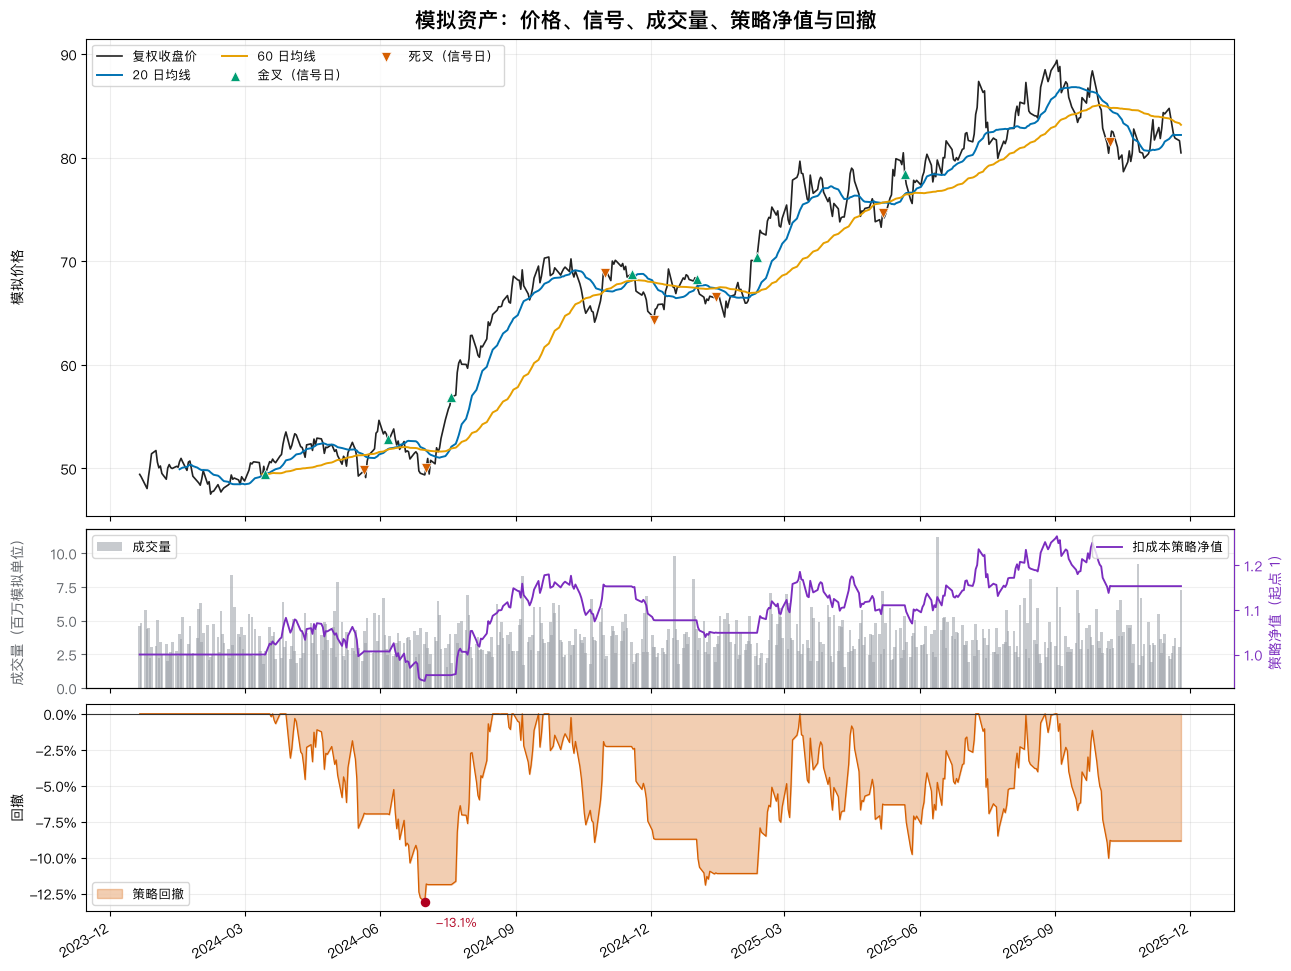

In [13]:
# 创建 3 个主 Axes；constrained_layout 自动为标题、图例和旋转日期留空间。
import matplotlib.dates as mdates
from matplotlib.ticker import PercentFormatter

fig, axes = plt.subplots(
    3,
    1,
    figsize=(12.8, 9.6),
    sharex=True,
    gridspec_kw={"height_ratios": [3.0, 1.0, 1.3]},
    constrained_layout=True,
)
ax_price, ax_volume, ax_drawdown = axes

# 面板 1：价格、两条均线和信号发现日。
ax_price.plot(
    result.index,
    result["adj_close"],
    color="#222222",
    linewidth=1.2,
    label=plot_labels["price"],
)
ax_price.plot(
    result.index,
    result["ma20"],
    color="#0072B2",
    linewidth=1.4,
    label=plot_labels["ma20"],
)
ax_price.plot(
    result.index,
    result["ma60"],
    color="#E69F00",
    linewidth=1.4,
    label=plot_labels["ma60"],
)
ax_price.scatter(
    result.index[result["golden_cross"]],
    result.loc[result["golden_cross"], "adj_close"],
    marker="^",
    s=52,
    color="#009E73",
    edgecolor="white",
    linewidth=0.5,
    zorder=4,
    label=plot_labels["golden"],
)
ax_price.scatter(
    result.index[result["death_cross"]],
    result.loc[result["death_cross"], "adj_close"],
    marker="v",
    s=52,
    color="#D55E00",
    edgecolor="white",
    linewidth=0.5,
    zorder=4,
    label=plot_labels["death"],
)
ax_price.set_ylabel(plot_labels["price_axis"])
ax_price.legend(
    loc="upper left",
    ncol=3,
    fontsize=9,
)
ax_price.grid(alpha=0.22)

# 面板 2 左轴：成交量，换算为百万模拟单位，避免难读的大整数。
volume_million = result["volume"] / 1_000_000
ax_volume.bar(
    result.index,
    volume_million,
    width=1.8,
    color="#9AA0A6",
    alpha=0.55,
    label=plot_labels["volume"],
)
ax_volume.set_ylabel(
    plot_labels["volume_axis"],
    color="#5F6368",
)
ax_volume.tick_params(
    axis="y",
    colors="#5F6368",
)
ax_volume.legend(
    loc="upper left",
    fontsize=9,
)
ax_volume.grid(axis="y", alpha=0.18)

# 面板 2 右轴：明确画扣成本策略净值，而不是归一化价格。
ax_strategy_nav = ax_volume.twinx()
ax_strategy_nav.plot(
    result.index,
    result["strategy_nav"],
    color="#7B2CBF",
    linewidth=1.35,
    label=plot_labels["strategy_nav"],
)
ax_strategy_nav.set_ylabel(
    plot_labels["nav_axis"],
    color="#7B2CBF",
)
ax_strategy_nav.tick_params(
    axis="y",
    colors="#7B2CBF",
)
ax_strategy_nav.spines["right"].set_color("#7B2CBF")
ax_strategy_nav.legend(
    loc="upper right",
    fontsize=9,
)

# 面板 3：由同一张表中的 strategy_drawdown 填充到 0。
ax_drawdown.fill_between(
    result.index,
    result["strategy_drawdown"].to_numpy(dtype=float),
    0,
    color="#D55E00",
    alpha=0.30,
    label=plot_labels["drawdown"],
)
ax_drawdown.plot(
    result.index,
    result["strategy_drawdown"],
    color="#D55E00",
    linewidth=0.9,
)
ax_drawdown.axhline(
    0,
    color="#333333",
    linewidth=0.8,
)
ax_drawdown.scatter(
    [max_drawdown_date],
    [max_drawdown],
    color="#B00020",
    s=34,
    zorder=5,
)
ax_drawdown.annotate(
    f"{max_drawdown:.1%}",
    xy=(max_drawdown_date, max_drawdown),
    xytext=(8, -18),
    textcoords="offset points",
    color="#B00020",
    fontsize=9,
)
ax_drawdown.set_ylabel(plot_labels["drawdown_axis"])
ax_drawdown.yaxis.set_major_formatter(
    PercentFormatter(1.0)
)
ax_drawdown.legend(
    loc="lower left",
    fontsize=9,
)
ax_drawdown.grid(alpha=0.22)

# 日期必须仍是 DatetimeIndex，locator/formatter 才按真实时间工作。
ax_drawdown.xaxis.set_major_locator(
    mdates.MonthLocator(interval=3)
)
ax_drawdown.xaxis.set_major_formatter(
    mdates.DateFormatter("%Y-%m")
)
plt.setp(
    ax_drawdown.get_xticklabels(),
    rotation=30,
    ha="right",
)

fig.suptitle(
    plot_labels["title"],
    fontsize=15,
    # 某些 macOS 中文字体没有名为 bold 的独立字重；直接使用 600
    # 可保持标题层级，同时避免 Matplotlib 的字体回退提示。
    fontweight=600,
)
fig.align_ylabels(axes)

# 保存前完成全部格式调整；保存后检查文件真实存在且非空。
chart_path = OUTPUT_DIR / "40_strategy_dashboard.png"
fig.savefig(
    chart_path,
    dpi=170,
    bbox_inches="tight",
    facecolor="white",
)

assert len(fig.axes) == 4  # 3 个主轴 + 1 个 twinx 右轴
assert chart_path.exists()
assert chart_path.stat().st_size > 0
print("图表已保存：", chart_path)
print("图片字节数：", chart_path.stat().st_size)
plt.show()
plt.close(fig)

## 15. 图后审计：展示数据与绘图数据必须一致

保存图片不是验收终点。下面再次检查：

- 所有关键列都属于同一 `result`；
- 结果表没有重复日期；
- 图中信号数量等于结果表事件数量；
- 图中回撤最小点来自扣成本策略净值。

图形不能独立证明这些关系，断言和带标签表格才是证据。

In [14]:
# 明确列出最终图所依赖的字段，避免误接另一张临时表。
plot_columns = [
    "adj_close",
    "volume",
    "ma20",
    "ma60",
    "golden_cross",
    "death_cross",
    "strategy_nav",
    "strategy_drawdown",
]
assert set(plot_columns).issubset(result.columns)
assert result.index.is_unique
assert result.index.is_monotonic_increasing
assert int(result["golden_cross"].sum()) == len(
    result.loc[result["golden_cross"]]
)
assert int(result["death_cross"].sum()) == len(
    result.loc[result["death_cross"]]
)
assert result["strategy_drawdown"].idxmin() == max_drawdown_date

print("绘图字段审计通过：", plot_columns)
result[plot_columns].tail(3)

绘图字段审计通过： ['adj_close', 'volume', 'ma20', 'ma60', 'golden_cross', 'death_cross', 'strategy_nav', 'strategy_drawdown']


,adj_close,volume,ma20,ma60,golden_cross,death_cross,strategy_nav,strategy_drawdown
date,,,,,,,,
2025-11-21,81.9017,3756601,82.205105,83.462565,False,False,1.153342,-0.088456
2025-11-24,81.6552,3042731,82.213330,83.338652,False,False,1.153342,-0.088456
2025-11-25,80.4798,7287501,82.209195,83.189495,False,False,1.153342,-0.088456


## 16. 量化意义与方法边界

- 同一结果表能减少错位，但不能替代对复权、时区、交易日历和字段单位的检查。
- `sharex=True` 只共享显示轴，不会自动连接或重采样不同数据源。
- `twinx()` 会引入第二套纵轴；若单位、颜色和图例不清晰，读者容易误判同步关系。
- `MonthLocator` 只减少刻度密度，不会删除行情点；把日期先转成分类字符串会失去真实时间间隔语义。
- 中文标题依赖字体字形；缺字体时应安装可追溯字体或使用英文回退，而不是屏蔽 warning。
- MA60 前 59 行为空是算法热身期，不应填 0 后制造交叉。
- 图上的金叉/死叉是收盘后发现的事件，不等于同日收盘成交。
- 本例用昨日状态乘今日 close-to-close 收益，只是无同收盘泄漏的简化执行模型，不是订单级回测。
- `buy_hold_nav` 是归一化价格；`strategy_nav` 才包含信号、持仓、收益和成本。二者不可共用模糊的“净值”标签。
- 回撤描述已发生路径，不能估计未来最大亏损；最大回撤还应结合持续时间和恢复时间。
- 成交量放大不能证明“机构买入/卖出”，OHLCV 不包含交易者身份。
- 本例没有税费差异、滑点、冲击、停牌、涨跌停、分红现金流和参数样本外验证，不构成真实策略证据。
- 可视化用于发现和沟通问题；显著性、稳健性、基准和样本外表现仍需单独检验。

## 17. 可复用结论与练习

```text
原始 OHLCV → 索引/价格/成交量契约
           → 同一 result 表
           → 历史均线 → 交叉事件
           → 信号滞后 → 持仓/换手/成本
           → 策略净值 → 峰值/回撤
           → 带标签指标 → 多面板图
```

练习：

1. 把持仓从 `shift(1)` 改成不滞后，比较结果并指出为何同收盘执行不成立。
2. 分别设置 0、5 bp、20 bp 成本，比较毛净值差和换手；不要只看最终收益。
3. 把第二面板的双轴拆成两个独立面板，比较可读性和视觉相关性。
4. 构造缺少一个交易日的成交量 Series，证明 `sharex=True` 不会替数据对齐。
5. 计算回撤持续时间和恢复日期，并核对最大回撤区间，而不只标记谷底。
6. 将样本拆成前后两段，只在前段选择均线参数，再在后段展示，避免用全样本挑最好看的图。